[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR/blob/main/colab_dae_grids_2.ipynb)

# Part A: completing the DAE search (A2)

Continues `colab_dae_grids.ipynb` (grids 1-5) from its choice after stage 2 (dropout 0.1, weight decay 0.01), the same way: every combination of a grid, by **val k-NN top-1**, the winner carried to the next grid.

- **Grid 6, more corruption:** a second noise on top of the winner × its level × combined augmentations (flip with rotation and color jitter).
- **Grid 7, the edges:** the winners of conv 2 (48) and of the patch size (4) were the smallest values tried, so smaller ones.

**Stage 1** and **stage 2** as in `colab_dae_grids.ipynb`. The 5 best of grids 6 and 7 train on all the images for 20 epochs, and compete with the choice of grids 1-5 and with it at dropout 0.2 and 0.3 (`tuning_choice.json`, kept as `"dae_grids_1_5"`); the best becomes `"dae"`. The last cell draws the A2 plot over the trials of both notebooks.

48 + 6 = 54 combinations, 44 new runs: stage 1 about 1.2 hours, stage 2 about 1.5 hours. It can run on a second runtime while `colab_dae_grids.ipynb` finishes: stage 2 here needs its choice, about 1.2 hours later.

## Setup
Downloads the repository (or pulls the latest code), installs it and checks the GPU.

In [1]:
import os

REPO = "/content/Representation-Learning-Midterm-DAE-SimCLR"
if not os.path.exists(REPO):
    !git clone https://github.com/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR.git {REPO}
os.chdir(REPO)
!git pull
!git log --oneline -1

remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 8 (delta 4), reused 7 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (8/8), 680.76 KiB | 10.31 MiB/s, done.
From https://github.com/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR
   13323c5..20e8c40  main       -> origin/main
Updating 13323c5..20e8c40
Fast-forward
 colab_dae_grids.ipynb                          |  1951 +++-
 colab_dae_grids_2.ipynb                        |    16 +-
 colab_tuning.ipynb                             |   130 -
 colab_final.ipynb => history/colab_final.ipynb |     0
 colab_partA.ipynb => history/colab_partA.ipynb |     0
 history/colab_tuning.ipynb                     | 12708 +++++++++++++++++++++++
 6 files changed, 14643 insertions(+), 162 deletions(-)
 delete mode 100644 colab_tuning.ipynb
 rename colab_final.ipynb => history/colab_final.ipynb (100%)
 rename colab_partA.ipynb => history/colab

In [2]:
%pip install -q -r requirements.txt

import torch
assert torch.cuda.is_available(), "No GPU. Runtime → Change runtime type → L4 GPU, then rerun this cell."
print(torch.cuda.get_device_name(0), "|", os.cpu_count(), "CPU cores")

NVIDIA L4 | 12 CPU cores


## Drive
Every run writes to `midterm_runs`, next to the earlier runs. Stage 1 runs have `search_pretrain` in their folder name, stage 2 runs `tune_pretrain`.

In [3]:
from google.colab import drive

drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע"
OUT = f"{DRIVE_DIR}/midterm_runs"
assert os.path.isdir(OUT), f"no folder {OUT}"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## TensorBoard
Filter the runs with `search_pretrain` or `tune_pretrain`, then *Toggle all runs*. `epoch/val_knn_top1` and `epoch/val_loss` compare the trials, IMAGES shows the noisy inputs and the reconstructions, the TEXT tab each run's `run_info`.

In [4]:
%load_ext tensorboard
%tensorboard --logdir "{OUT}"

Reusing TensorBoard on port 6006 (pid 1916), started 0:38:47 ago. (Use '!kill 1916' to kill it.)

<IPython.core.display.Javascript object>

## The search
`grid_search_dae` trains one DAE for every combination of its grid (the rest at the best so far), keeps the best by val k-NN in `best`, and adds every trial to `results`. `train` runs train.py only if the run has no `results.json` yet, so combinations that are the same run (the patch size of a noise without patches) are trained once and read from Drive.

In [5]:
import importlib
import itertools
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

STAGE1 = "--mode pretrain --search --data_fraction 0.1"  # 10% of the images, 10 epochs, a 10,000-image k-NN bank
STAGE2 = "--mode pretrain --tune --num_epochs 20"  # all the images, the full bank, val only (no test)
CHOICE_FILE = f"{OUT}/tuning_choice.json"
# The choice of colab_dae_grids.ipynb (after stage 2); every grid starts from the best so far
best = {"noise_type": "patch_mask", "noise_level": 0.5, "patch_size": 4, "conv1": 48, "conv2": 48,
        "latent_dim": 384, "dropout": 0.1, "augment": "flip", "batch_size": 512, "optimizer": "adamw",
        "activation": "gelu", "lr": 0.001, "wd": 0.01, "scheduler": "none", "noise_type2": "none",
        "noise_level2": 0.0}
results = []  # every trial of stage 1


def flags_of(params):
    """The train.py flags of one DAE."""
    p = dict(params)
    return f"--channels {p.pop('conv1')} {p.pop('conv2')} " + " ".join(f"--{k} {v}" for k, v in p.items())


def folder_of(flags):
    """The run folder train.py uses for these flags (run_info.folder_name)."""
    import config, utils, run_info
    for module in (config, utils, run_info):
        importlib.reload(module)
    sys.argv = ["train.py", *flags.split(), "--output_dir", OUT]
    return f"{OUT}/{run_info.folder_name(utils.parse_args().mode)}"


def train(flags):
    """One run of train.py (skipped if it finished before): its val numbers and its folder."""
    if not os.path.exists(f"{folder_of(flags)}/results.json"):
        !python train.py {flags} --output_dir "{OUT}"
    folder = folder_of(flags)
    with open(f"{folder}/results.json") as f:
        return {**json.load(f), "run": os.path.basename(folder)}


def grid_search_dae(**grid):
    """Every combination of grid, the rest at the best so far; the best by val k-NN goes on."""
    rows = []
    for values in itertools.product(*grid.values()):
        params = {**best, **dict(zip(grid, values))}
        r = train(f"{STAGE1} {flags_of(params)}")
        rows.append({**params, "val_knn": r["val_knn_top1"], "val_loss": r["val_loss"], "run": r["run"]})
    results.extend(rows)
    top = max(rows, key=lambda row: row["val_knn"])
    best.update({k: top[k] for k in grid})  # the winner goes on to the next grid
    print("best so far:", best)
    table = pd.DataFrame(rows).sort_values("val_knn", ascending=False)
    display(table[[*grid, "val_knn", "val_loss"]].head(10).round(4))
    return table

## Grid 6, more corruption
A second noise on top of the winner (pixel noises only: the winner already hides patches) × its level × the augmentation, flip alone or with rotation and color jitter (crop lost in grid 3): 4 × 3 × 4 = 48. The 3 levels of "none" are the same run, trained once: 40 runs.

In [6]:
results_6 = grid_search_dae(noise_type2=["none", "mask", "salt_pepper", "gaussian"], noise_level2=[0.1, 0.2, 0.3],
                            augment=["flip", "flip_rotate", "flip_jitter", "flip_rotate_jitter"])

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
DenoisingAutoEncoder(
  (encoder): Sequential(
    (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(48, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=12288, out_features=384, b

,noise_type2,noise_level2,augment,val_knn,val_loss
0,none,0.1,flip,0.0533,0.2989
4,none,0.2,flip,0.0533,0.2989
8,none,0.3,flip,0.0533,0.2989
40,gaussian,0.2,flip,0.0528,0.2818
45,gaussian,0.3,flip_rotate,0.0527,0.2940
36,gaussian,0.1,flip,0.0524,0.2801
41,gaussian,0.2,flip_rotate,0.0522,0.2915
18,mask,0.2,flip_jitter,0.0520,0.2972
44,gaussian,0.3,flip,0.0518,0.3003
47,gaussian,0.3,flip_rotate_jitter,0.0516,0.2991


## Grid 7, the edges
Conv 2 won with 48 and the patch size with 4, the smallest values of their grids: 3 × 2 = 6.

In [7]:
results_7 = grid_search_dae(conv2=[32, 40, 48], patch_size=[2, 4])

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
DenoisingAutoEncoder(
  (encoder): Sequential(
    (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(48, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=8192, out_features=384, bi

,conv2,patch_size,val_knn,val_loss
5,48,4,0.0533,0.2989
4,48,2,0.0481,0.2568
3,40,4,0.0474,0.2891
2,40,2,0.0466,0.2674
1,32,4,0.0437,0.2957
0,32,2,0.0424,0.2737


## Stage 2
The 5 best DAEs of grids 6 and 7 on all the images for 20 epochs, against the choice of grids 1-5 (trained there, read from Drive), and that choice with dropout 0.2 and 0.3: on 10% of the images for 10 epochs dropout 0 won, on all of them 0.1, so larger values are tried on all of them. The best by val k-NN is the choice.

In [8]:
top5 = pd.DataFrame(results).drop_duplicates(subset="run").nlargest(5, "val_knn")  # 5 different runs
choices = json.load(open(CHOICE_FILE)) if os.path.exists(CHOICE_FILE) else {}
assert "dae" in choices, "run colab_dae_grids.ipynb to the end first: its choice competes here"
choices.setdefault("dae_grids_1_5", choices["dae"])  # the choice of grids 1-5, kept
first = {**choices["dae_grids_1_5"], "noise_type2": "none", "noise_level2": 0.0}  # one noise there
first.pop("num_epochs")
finals = []
for params in [first, {**first, "dropout": 0.2}, {**first, "dropout": 0.3}, *top5[list(best)].to_dict("records")]:
    r = train(f"{STAGE2} {flags_of(params)}")
    finals.append({**params, "val_knn": r["val_knn_top1"], "val_loss": r["val_loss"], "run": r["run"]})
finals = pd.DataFrame(finals).drop_duplicates(subset="run").sort_values("val_knn", ascending=False)
display(finals.round(4))

choice = {**finals[list(best)].to_dict("records")[0], "num_epochs": 20}
choices["dae"] = choice
with open(CHOICE_FILE, "w") as f:
    json.dump(choices, f, indent=1)
print("the DAE:", choice)

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
DenoisingAutoEncoder(
  (encoder): Sequential(
    (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(48, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=12288, out_features=384, b

,noise_type,noise_level,patch_size,conv1,conv2,latent_dim,dropout,augment,batch_size,optimizer,activation,lr,wd,scheduler,noise_type2,noise_level2,val_knn,val_loss,run
2,patch_mask,0.5,4,48,48,384,0.3,flip,512,adamw,gelu,0.001,0.01,none,none,0.0,0.0938,0.2196,date24112026_time021632_CNN3_tune_pretrain_DAE...
1,patch_mask,0.5,4,48,48,384,0.2,flip,512,adamw,gelu,0.001,0.01,none,none,0.0,0.0931,0.2136,date24112026_time020521_CNN3_tune_pretrain_DAE...
5,patch_mask,0.5,4,48,48,384,0.1,flip_rotate,512,adamw,gelu,0.001,0.01,none,gaussian,0.3,0.0913,0.2088,date24112026_time023911_CNN3_tune_pretrain_DAE...
4,patch_mask,0.5,4,48,48,384,0.1,flip,512,adamw,gelu,0.001,0.01,none,gaussian,0.2,0.0890,0.2021,date24112026_time022748_CNN3_tune_pretrain_DAE...
0,patch_mask,0.5,4,48,48,384,0.1,flip,512,adamw,gelu,0.001,0.01,none,none,0.0,0.0889,0.1986,date23112026_time195243_CNN3_tune_pretrain_DAE...
7,patch_mask,0.5,4,48,48,384,0.1,flip_rotate,512,adamw,gelu,0.001,0.01,none,gaussian,0.2,0.0877,0.2336,date24112026_time030412_CNN3_tune_pretrain_DAE...
6,patch_mask,0.5,4,48,48,384,0.1,flip,512,adamw,gelu,0.001,0.01,none,gaussian,0.1,0.0867,0.1973,date24112026_time025254_CNN3_tune_pretrain_DAE...


the DAE: {'noise_type': 'patch_mask', 'noise_level': 0.5, 'patch_size': 4, 'conv1': 48, 'conv2': 48, 'latent_dim': 384, 'dropout': 0.3, 'augment': 'flip', 'batch_size': 512, 'optimizer': 'adamw', 'activation': 'gelu', 'lr': 0.001, 'wd': 0.01, 'scheduler': 'none', 'noise_type2': 'none', 'noise_level2': 0.0, 'num_epochs': 20}


## A2: reconstruction against k-NN
Every stage 1 trial of both notebooks (`dae_grid_results.csv` from grids 1-5, and grids 6 and 7), colored by noise, saved as `dae_grid_results_all.csv`. The noise types have different reconstruction tasks, so compare within a color.

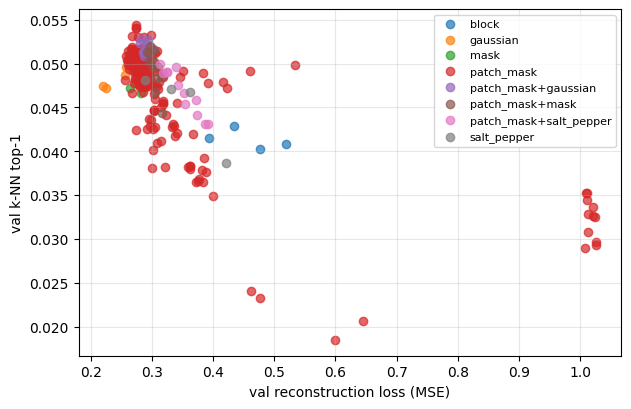

Spearman correlation: -0.644


In [9]:
trials = pd.concat([pd.read_csv(f"{OUT}/dae_grid_results.csv"), pd.DataFrame(results)])
trials = trials.drop_duplicates(subset="run").fillna({"noise_type2": "none", "noise_level2": 0.0})
trials.to_csv(f"{OUT}/dae_grid_results_all.csv", index=False)
trials["noise"] = trials["noise_type"].where(trials["noise_type2"] == "none", trials["noise_type"] + "+" + trials["noise_type2"])
fig, ax = plt.subplots(figsize=(7, 4.5))
for noise, group in trials.groupby("noise"):
    ax.scatter(group["val_loss"], group["val_knn"], label=noise, alpha=0.7)
ax.set_xlabel("val reconstruction loss (MSE)")
ax.set_ylabel("val k-NN top-1")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()
print("Spearman correlation:", round(trials["val_loss"].corr(trials["val_knn"], method="spearman"), 3))